# 01 — Problem understanding dan EDA
Klasifikasi **visual** halaman dokumen ke 16 kelas menggunakan PyTorch. Input model hanya piksel; nama file, ID, dan label contoh submission bukan fitur.

Alur mengikuti proyek referensi: EDA → modeling → submission, dengan implementasi bersama di `scripts/`. Bobot penilaian repositori adalah 70%, public leaderboard 10%, dan private leaderboard 20%. Nama metrik leaderboard belum tersedia; laporkan accuracy dan macro-F1 secara terpisah.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
assert (ROOT / 'scripts').is_dir(), 'Buka notebook dari root proyek atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.preprocess import data_directory, read_metadata
DATA = data_directory()
train, test, sample = read_metadata(DATA)

## Struktur dan kualitas metadata
Periksa jumlah baris, nilai kosong, keunikan ID, dan pemetaan label. Loader mendukung ekstraksi normal maupun folder `train/train` dan `test/test`.

In [2]:
display(train.head())
display(pd.DataFrame({'rows': [len(train), len(test)], 'unique_ids': [train.id.nunique(), test.id.nunique()]}, index=['train', 'test']))
display(train.isna().sum().to_frame('missing'))

,id,filename,class_name,label
0,train_00001,train/resume/50497291-7292.tif,resume,12
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14
3,train_00004,train/scientific_publication/10343650_10343655...,scientific_publication,13
4,train_00005,train/specification/2057960699_2057960701.tif,specification,15


,rows,unique_ids
train,32003,32003
test,7994,7994


,missing
id,0
filename,0
class_name,0
label,0


## Audit seluruh gambar
Decode semua TIFF; hitung dimensi, jumlah halaman, dan hash piksel. Gambar training yang tidak terbaca dicatat dan dikeluarkan dari kedua split; gambar test yang tidak terbaca menghentikan pipeline. Cache menggunakan grayscale dan padding putih, tanpa memotong teks.

In [3]:
from scripts.preprocess import prepare_data, verified_cache
if not (ROOT / 'data/cache_128/manifest.json').exists():
    prepare_data(DATA, image_size=128)
verified_cache(DATA, 128)
audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
display({key: audit[key] for key in ['train_rows', 'test_rows', 'usable_training_rows', 'unreadable_images', 'excluded_training_images', 'train_duplicate_pixel_rows', 'conflicting_duplicate_groups', 'test_images_matching_train_pixels', 'multipage_images']})

{'train_rows': 32003,
 'test_rows': 7994,
 'usable_training_rows': 32002,
 'unreadable_images': 1,
 'excluded_training_images': ['train_08795'],
 'train_duplicate_pixel_rows': 48,
 'conflicting_duplicate_groups': 3,
 'test_images_matching_train_pixels': 25,
 'multipage_images': 0}

## Distribusi target
Bandingkan kelas terbanyak dan tersedikit sebelum memutuskan perlunya class weighting. Bobot kelas tidak diterapkan otomatis pada dataset yang hampir seimbang.

,,count
label,class_name,
0,advertisement,2012
1,budget,2004
2,email,2013
3,file_folder,2022
4,form,2005
5,handwritten,2026
6,invoice,1982
7,letter,1972
8,memo,1994


Rasio kelas terbesar/terkecil: 1.055


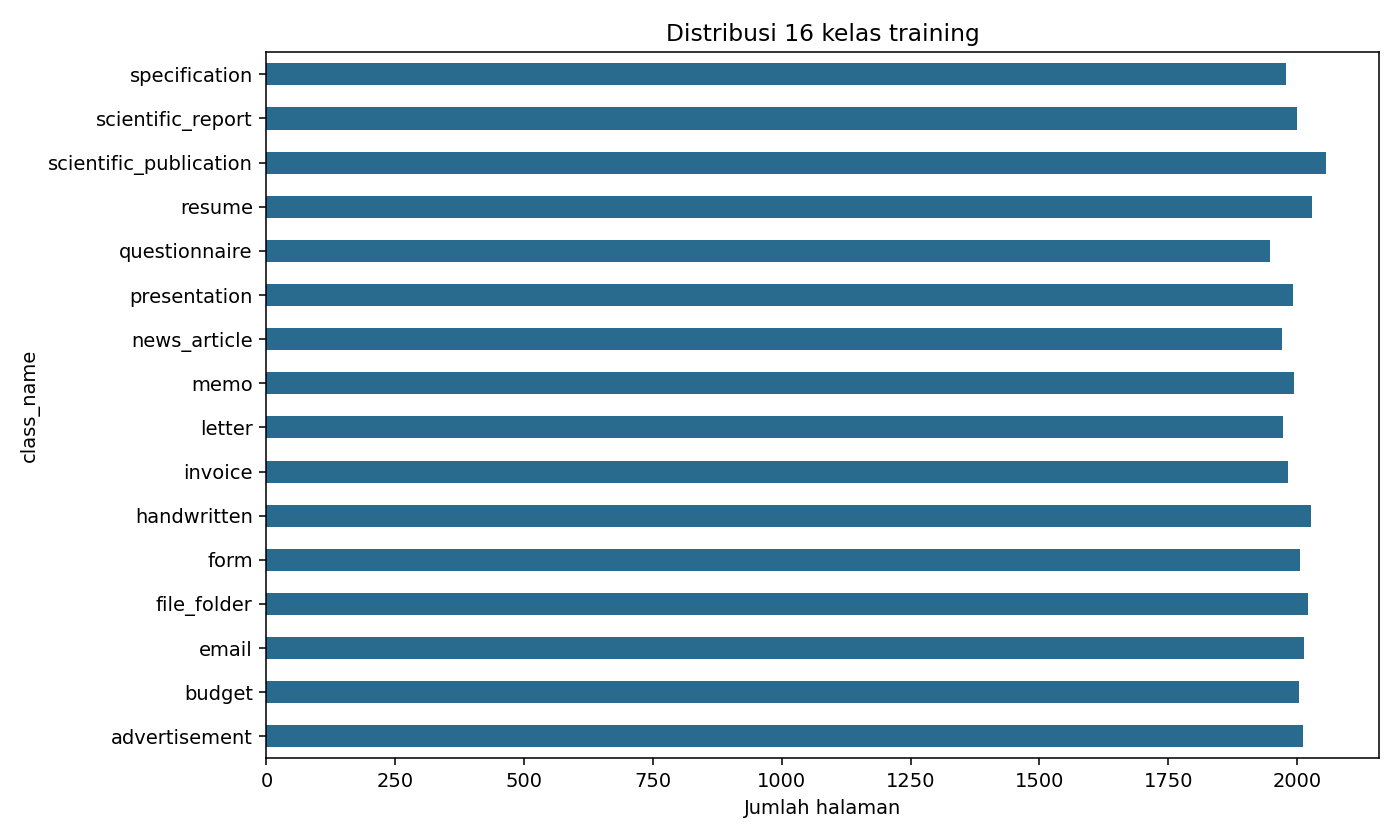

In [4]:
counts = train.groupby(['label', 'class_name']).size().rename('count')
display(counts.to_frame())
print(f'Rasio kelas terbesar/terkecil: {counts.max()/counts.min():.3f}')
display(Image(filename=str(ROOT / 'reports/figures/class_distribution.png')))

## Sampel visual dan rasio aspek
Perhatikan layout kolom, tabel, kop surat, serta dokumen landscape. Pada resolusi 128, teks kecil kehilangan detail; baseline terutama menguji informasi layout.

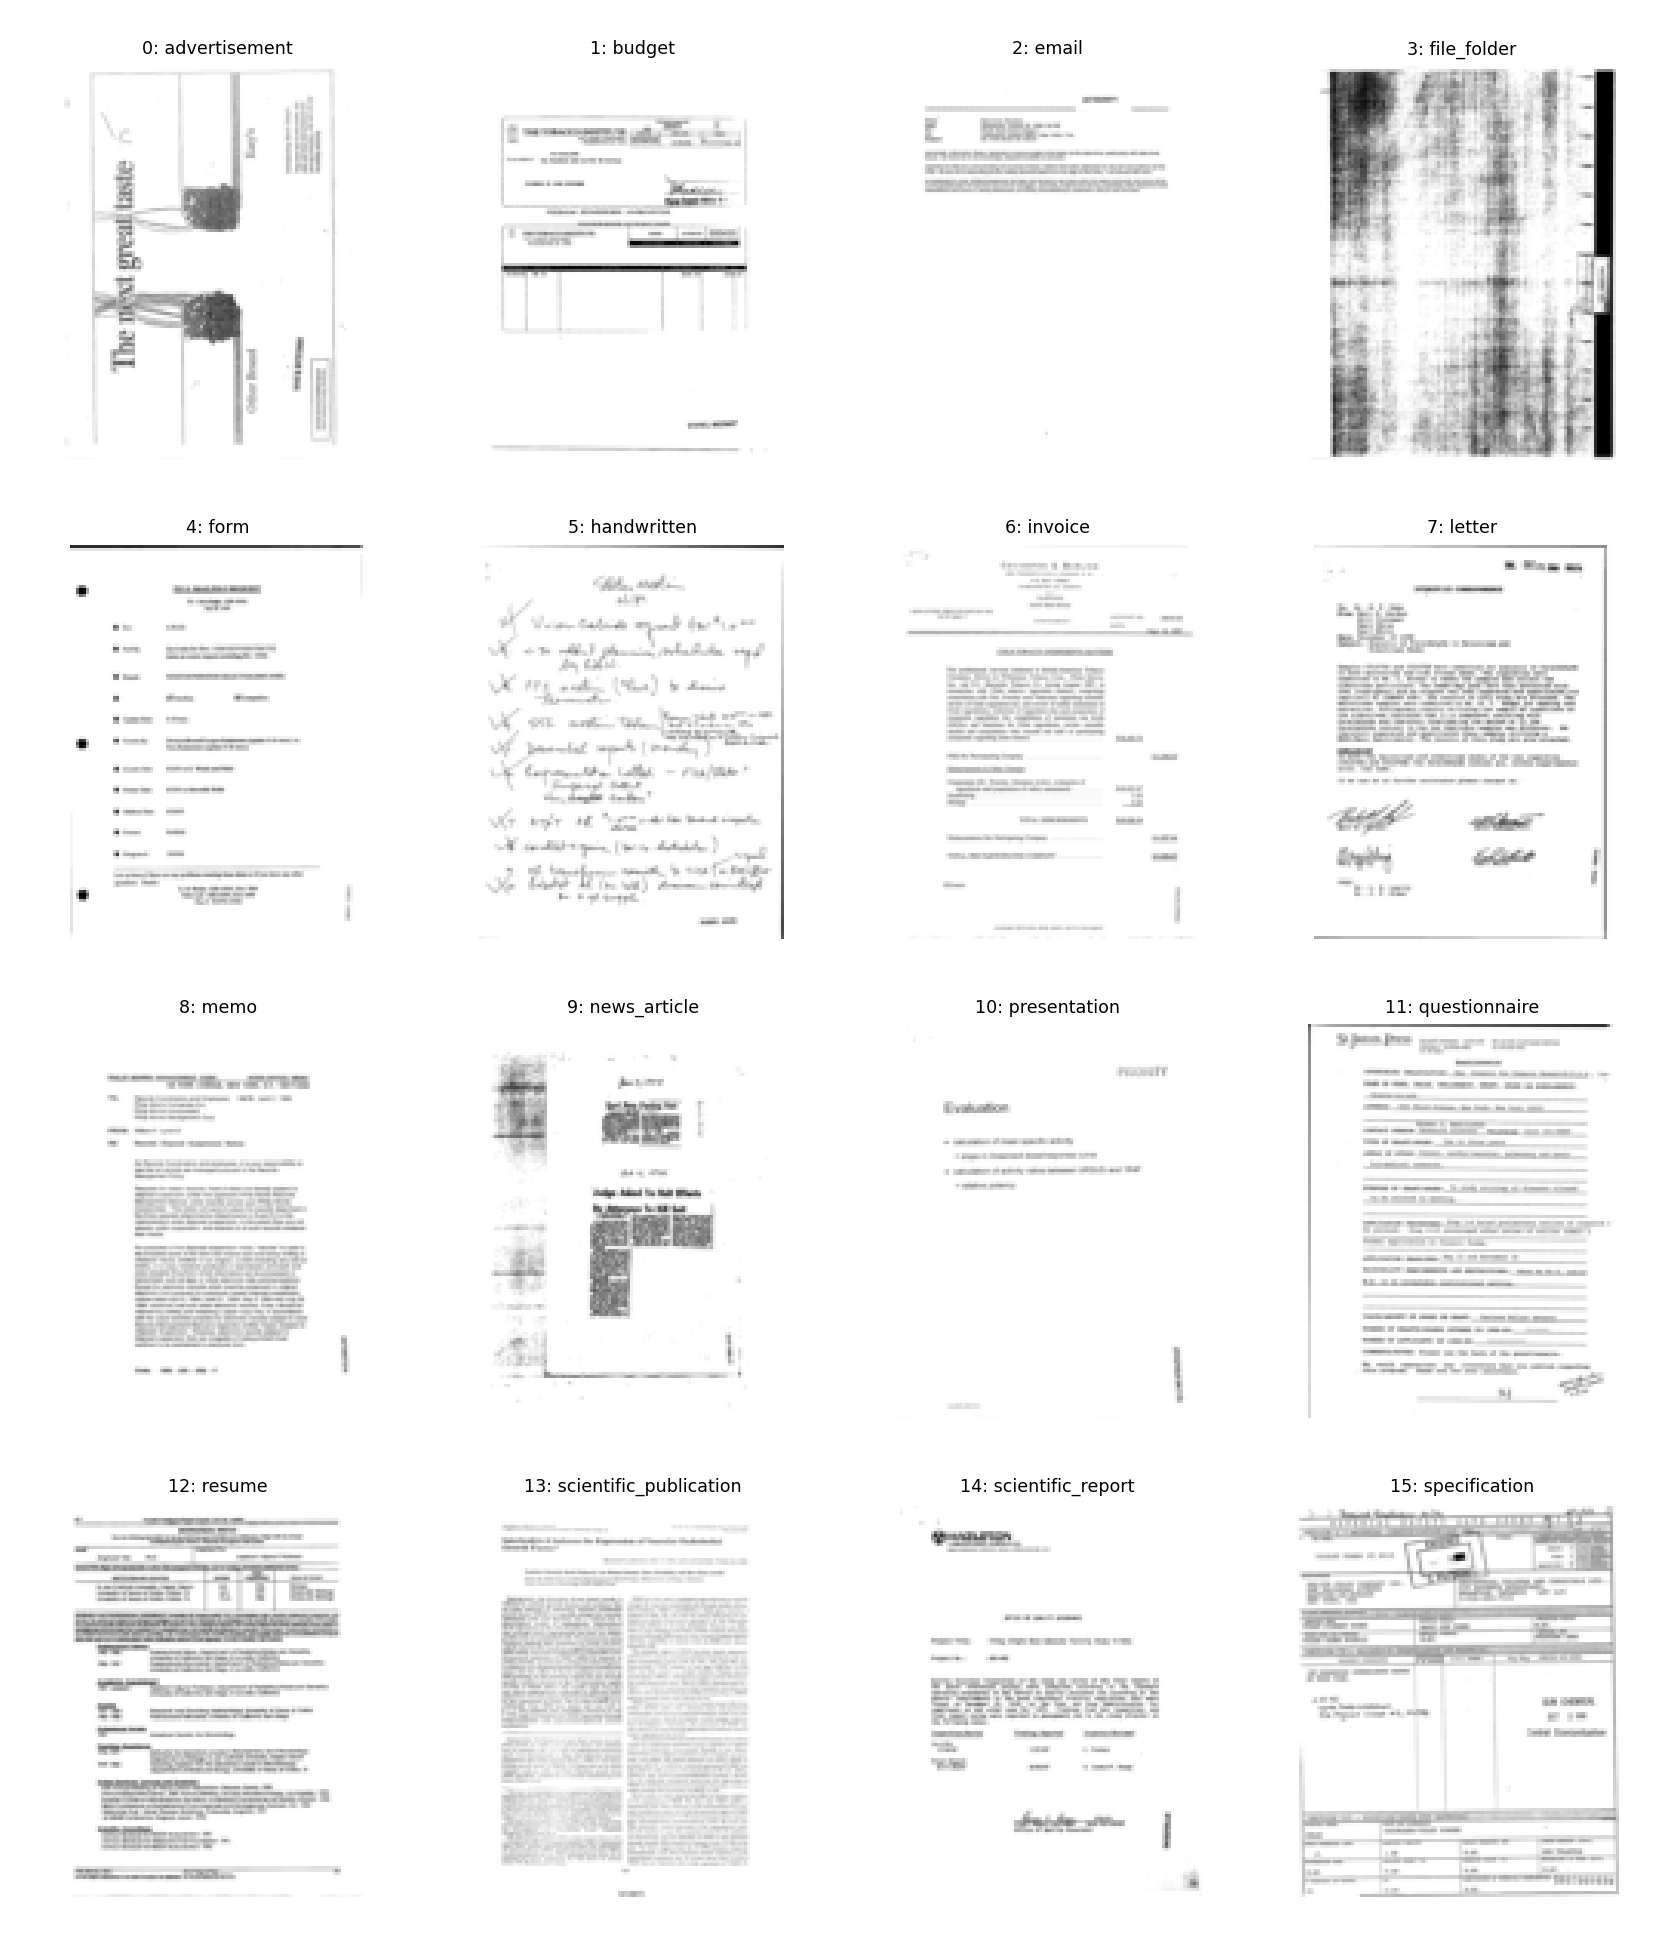

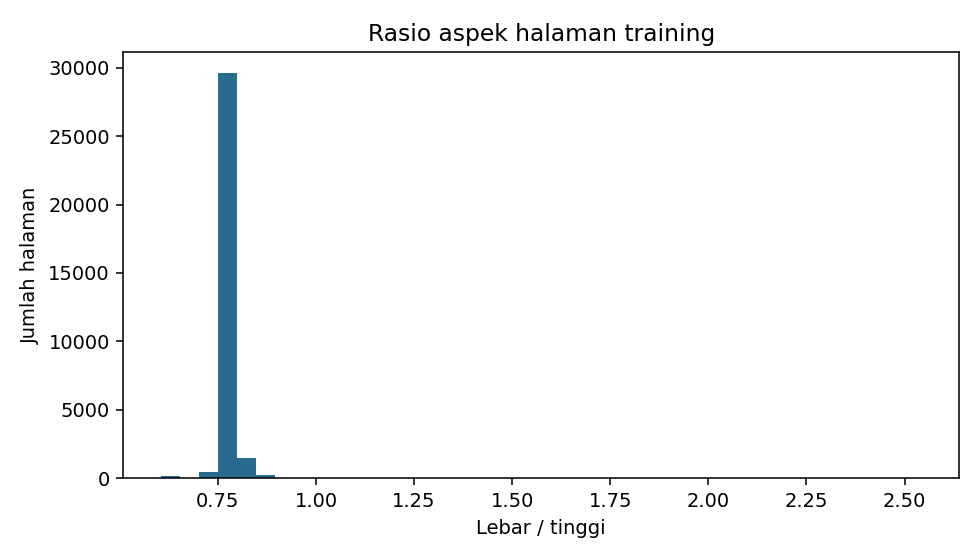

In [5]:
display(Image(filename=str(ROOT / 'reports/figures/sample_documents.png')))
display(Image(filename=str(ROOT / 'reports/figures/aspect_ratios.png')))

## Interpretasi dan keputusan preprocessing
Kelas relatif seimbang, sehingga accuracy berguna sebagai ringkasan dan macro-F1 memeriksa pemerataan performa kelas. Padding mempertahankan rasio aspek dan isi halaman. Hindari flip dan crop agresif karena dapat menghilangkan header atau mengubah arah baca. Kontras ringan hanya diterapkan pada training. TIFF multipage menggunakan halaman pertama.

Hash piksel yang identik menjadi satu grup split. Ini mencegah kebocoran duplikat persis, tetapi tidak menjamin halaman dari dokumen sumber yang sama selalu bersama: ID dokumen sumber tidak tersedia. Nama file tidak diasumsikan sebagai ID grup dokumen. Test digunakan untuk audit teknis dan prediksi, tidak untuk pemilihan model.